# FYS4480/9480, week 47: coupled-cluster doubles for the pairing model

Companion notebook to the slides `week47.tex`. Everything here is plain `numpy`, written as a
handful of small classes:

| class | what it holds |
|---|---|
| `PairingModel` | the Hamiltonian: spin-orbital $h$, antisymmetrised $\langle pq\Vert rs\rangle$, Fock matrix, reference energy, and the exact energy from the seniority-zero space |
| `CCD` | the ten terms of the CCD amplitude equation, the residual, the energy and a damped Jacobi solver |
| `DeterminantSpace` | a brute-force $e^{-T}He^{T}$ in the full space of determinants, used only to check the algebra |
| `PairCCD` | the same theory reduced to pair amplitudes $t_i^a$ (one number per occupied-empty pair of levels) |

The order follows the lectures: (1) the model, (2) the CCD equation term by term and its check
against the brute-force similarity transformation, (3) the pairing model solved, (4) what each
diagram contributes, (5) the reduction to pair amplitudes, (6) what CCD misses, (7) convergence of the
iteration, (8) a larger model space and the role of intermediates.

In [1]:
import itertools, time
import numpy as np
np.set_printoptions(precision=6, suppress=True, linewidth=120)

## 1. The pairing model

$$H=\xi\sum_{p\sigma}(p-1)\,a^\dagger_{p\sigma}a_{p\sigma}-\frac g2\sum_{pq}a^\dagger_{p+}a^\dagger_{p-}a_{q-}a_{q+},$$

with $p=1,\dots,L$ doubly degenerate levels. Spin orbital $2(p-1)$ is $(p,+)$ and $2(p-1)+1$ is $(p,-)$, the
$N$ lowest spin orbitals are occupied in the reference. The only non-zero antisymmetrised elements are
$\langle p{+}\,p{-}\Vert q{+}\,q{-}\rangle=-g/2$ and their antisymmetric partners. The Fock matrix is diagonal:
$f_{ii}=\varepsilon_i-g/2$ for occupied and $f_{aa}=\varepsilon_a$ for empty spin orbitals.

In [2]:
class PairingModel:
    """The pairing Hamiltonian in a spin-orbital basis, with its exact solution."""

    def __init__(self, levels=4, particles=4, g=1.0, xi=1.0):
        self.levels, self.particles, self.g, self.xi = levels, particles, g, xi
        self.n = 2 * levels                      # number of spin orbitals
        self.n_occ = particles
        self.h = np.diag([xi * (p // 2) for p in range(self.n)]).astype(float)
        self.v = np.zeros((self.n,) * 4)         # <pq||rs>, antisymmetrised
        for p in range(levels):
            for q in range(levels):
                a, b, c, d = 2 * p, 2 * p + 1, 2 * q, 2 * q + 1
                self.v[a, b, c, d] += -0.5 * g
                self.v[b, a, c, d] -= -0.5 * g
                self.v[a, b, d, c] -= -0.5 * g
                self.v[b, a, d, c] += -0.5 * g

    @property
    def fock(self):
        """f_pq = h_pq + sum_i <pi||qi>."""
        occ = range(self.n_occ)
        return self.h + sum(self.v[:, i, :, i] for i in occ)

    @property
    def reference_energy(self):
        occ = range(self.n_occ)
        return (sum(self.h[i, i] for i in occ)
                + 0.5 * sum(self.v[i, j, i, j] for i in occ for j in occ))

    def exact_energy(self, full_vector=False):
        """Ground state in the space of unbroken pairs (seniority zero).

        Basis: which levels carry a pair.  Diagonal: sum (2 eps_p - g/2);
        off-diagonal: -g/2 whenever two configurations differ by one pair."""
        G, npair = 0.5 * self.g, self.particles // 2
        confs = list(itertools.combinations(range(self.levels), npair))
        H = np.zeros((len(confs), len(confs)))
        for m, cm in enumerate(confs):
            H[m, m] = sum(2 * self.xi * p - G for p in cm)
            for k, ck in enumerate(confs):
                if len(set(cm) ^ set(ck)) == 2:
                    H[m, k] = -G
        e, c = np.linalg.eigh(H)
        return (e[0], c[:, 0], confs) if full_vector else e[0]


model = PairingModel(levels=4, particles=4, g=1.0)
f = model.fock
print("reference energy 2 - g      :", model.reference_energy)
print("diagonal of the Fock matrix :", np.diag(f))
print("off-diagonal Fock elements  :", abs(f - np.diag(np.diag(f))).max())
print("exact (seniority zero)      :", model.exact_energy())

reference energy 2 - g      : 1.0
diagonal of the Fock matrix : [-0.5 -0.5  0.5  0.5  2.   2.   3.   3. ]
off-diagonal Fock elements  : 0.0
exact (seniority zero)      : 0.6355484735755976


## 2. The CCD amplitude equation, term by term

With $T=T_2$ the doubles projection $\langle\Phi_{ij}^{ab}|(H_N[1+T_2+\tfrac12T_2^2])_c|\Phi_0\rangle=0$ has ten terms
(repeated indices summed, $P(ij)X_{ij}=X_{ij}-X_{ji}$):

| name | term | from |
|---|---|---|
| `drive` | $\langle ab\Vert ij\rangle$ | no $T$ |
| `fock_p` | $P(ab)\,f_{bc}t_{ij}^{ac}$ | $F_N T_2$ |
| `fock_h` | $-P(ij)\,f_{kj}t_{ik}^{ab}$ | $F_N T_2$ |
| `pp` | $\tfrac12\langle ab\Vert cd\rangle t_{ij}^{cd}$ | $V_N T_2$ |
| `hh` | $\tfrac12\langle kl\Vert ij\rangle t_{kl}^{ab}$ | $V_N T_2$ |
| `ring` | $P(ij)P(ab)\langle kb\Vert cj\rangle t_{ik}^{ac}$ | $V_N T_2$ |
| `Qa` | $\tfrac14\langle kl\Vert cd\rangle t_{ij}^{cd}t_{kl}^{ab}$ | $\tfrac12V_NT_2^2$ |
| `Qb` | $\tfrac12P(ij)P(ab)\langle kl\Vert cd\rangle t_{ik}^{ac}t_{jl}^{bd}$ | $\tfrac12V_NT_2^2$ |
| `Qc` | $-\tfrac12P(ab)\langle kl\Vert cd\rangle t_{ij}^{ac}t_{kl}^{bd}$ | $\tfrac12V_NT_2^2$ |
| `Qd` | $-\tfrac12P(ij)\langle kl\Vert cd\rangle t_{ik}^{ab}t_{jl}^{cd}$ | $\tfrac12V_NT_2^2$ |

The class below is a direct transcription. The amplitudes are stored as `t[i, j, a, b]`. The residual is the sum of
the ten terms; the Jacobi step divides it by $D_{ij}^{ab}=f_{ii}+f_{jj}-f_{aa}-f_{bb}$.

In [3]:
class CCD:
    """Coupled-cluster doubles for a Fock matrix f and antisymmetrised v = <pq||rs>."""

    names = ("drive", "fock_p", "fock_h", "pp", "hh", "ring", "Qa", "Qb", "Qc", "Qd")

    def __init__(self, f, v, n_occ):
        n = f.shape[0]
        o, u = slice(0, n_occ), slice(n_occ, n)
        self.no, self.nv = n_occ, n - n_occ
        self.foo, self.fvv = f[o, o], f[u, u]
        self.vvvoo = v[u, u, o, o]              # <ab||ij>
        self.vvvvv = v[u, u, u, u]              # <ab||cd>
        self.voooo = v[o, o, o, o]              # <kl||ij>
        self.vovvo = v[o, u, u, o]              # <kb||cj>
        self.voovv = v[o, o, u, u]              # <kl||cd>
        eo, ev = np.diag(self.foo), np.diag(self.fvv)
        self.D = (eo[:, None, None, None] + eo[None, :, None, None]
                  - ev[None, None, :, None] - ev[None, None, None, :])

    # ----- permutation operators acting on X[i, j, a, b]
    @staticmethod
    def Pij(x):
        return x - x.transpose(1, 0, 2, 3)

    @staticmethod
    def Pab(x):
        return x - x.transpose(0, 1, 3, 2)

    # ----- the ten terms
    def terms(self, t):
        es, Pij, Pab = np.einsum, self.Pij, self.Pab
        w = self.voovv
        return {
            "drive":  self.vvvoo.transpose(2, 3, 0, 1).copy(),
            "fock_p": Pab(es("bc,ijac->ijab", self.fvv, t)),
            "fock_h": -Pij(es("kj,ikab->ijab", self.foo, t)),
            "pp":     0.5 * es("abcd,ijcd->ijab", self.vvvvv, t),
            "hh":     0.5 * es("klij,klab->ijab", self.voooo, t),
            "ring":   Pij(Pab(es("kbcj,ikac->ijab", self.vovvo, t))),
            "Qa":     0.25 * es("klcd,ijcd,klab->ijab", w, t, t, optimize=True),
            "Qb":     0.5 * Pij(Pab(es("klcd,ikac,jlbd->ijab", w, t, t, optimize=True))),
            "Qc":     -0.5 * Pab(es("klcd,ijac,klbd->ijab", w, t, t, optimize=True)),
            "Qd":     -0.5 * Pij(es("klcd,ikab,jlcd->ijab", w, t, t, optimize=True)),
        }

    def residual(self, t, keep=None):
        """<Phi_ij^ab| Hbar |Phi_0>; `keep` selects a subset of the terms."""
        terms = self.terms(t)
        return sum(terms[k] for k in (keep or self.names))

    def energy(self, t):
        """Correlation energy 1/4 sum <ij||ab> t_ij^ab."""
        return 0.25 * float(np.einsum("ijab,ijab->", self.voovv, t))

    def first_order(self):
        """The MBPT amplitude <ab||ij>/D: the starting point of the iteration."""
        return self.vvvoo.transpose(2, 3, 0, 1) / self.D

    def antisymmetrise(self, t):
        """Project on the part antisymmetric in (i, j) and in (a, b): the only part T_2 depends on."""
        return 0.25 * self.Pij(self.Pab(t))

    def solve(self, mix=1.0, tol=1e-12, max_iter=2000, keep=None, verbose=False, project=True):
        """Damped Jacobi iteration t <- t + mix * R(t)/D, stopped on max|R|.

        With project=True the amplitudes are antisymmetrised after every step, which removes
        the rounding noise that would otherwise accumulate in the unphysical components."""
        t = self.first_order()
        history = []
        for it in range(1, max_iter + 1):
            R = self.residual(t, keep)
            history.append((self.energy(t), abs(R).max()))
            if verbose:
                print(f"{it:4d}  E_corr = {history[-1][0]: .12f}   max|R| = {history[-1][1]:.2e}")
            if history[-1][1] < tol:
                break
            if not np.isfinite(history[-1][1]) or history[-1][1] > 1e6:
                break
            t = t + mix * R / self.D
            if project:
                t = self.antisymmetrise(t)
        self.history, self.iterations = history, it
        self.converged = history[-1][1] < tol
        return t

### Check against the brute-force similarity transformation

Before using the equation we test it. `DeterminantSpace` builds the matrices of $H$ and of $T_2$ in the full space
of Slater determinants (bit strings), forms $e^{-T}He^{T}$ with the (finite) power series and projects on the
doubly excited determinants. It knows nothing about Wick's theorem or diagrams. Since
$\overline H=H+[H,T]+\tfrac12[[H,T],T]+\dots$, the three groups of terms can be checked separately.

In [4]:
class DeterminantSpace:
    """Brute-force second quantisation on bit strings, for validation only."""

    def __init__(self, n, n_particles):
        self.n, self.N = n, n_particles
        self.dets = [sum(1 << p for p in c) for c in itertools.combinations(range(n), n_particles)]
        self.index = {d: k for k, d in enumerate(self.dets)}
        self.ref = self.index[sum(1 << p for p in range(n_particles))]

    @staticmethod
    def _apply(ops, state):
        """ops = [('c', p), ('a', q), ...] applied right to left; returns (sign, state)."""
        sign = 1
        for kind, p in reversed(ops):
            occupied = (state >> p) & 1
            if (kind == 'a') != bool(occupied):
                return 0, None
            if bin(state & ((1 << p) - 1)).count("1") & 1:
                sign = -sign
            state ^= 1 << p
        return sign, state

    def hamiltonian(self, h, v):
        dim, n = len(self.dets), self.n
        H = np.zeros((dim, dim))
        nz1 = [(p, q) for p in range(n) for q in range(n) if h[p, q] != 0]
        nz2 = [idx for idx in itertools.product(range(n), repeat=4) if v[idx] != 0]
        for k, d in enumerate(self.dets):
            for p, q in nz1:
                s, e = self._apply([('c', p), ('a', q)], d)
                if s:
                    H[self.index[e], k] += s * h[p, q]
            for p, q, r, s_ in nz2:
                s, e = self._apply([('c', p), ('c', q), ('a', s_), ('a', r)], d)
                if s:
                    H[self.index[e], k] += 0.25 * s * v[p, q, r, s_]
        return H

    def cluster_operator(self, t):
        """Matrix of T_2 = 1/4 sum t_ij^ab a+_a a+_b a_j a_i."""
        dim, N = len(self.dets), self.N
        T = np.zeros((dim, dim))
        no, nv = t.shape[0], t.shape[2]
        for k, d in enumerate(self.dets):
            for i, j, a, b in itertools.product(range(no), range(no), range(nv), range(nv)):
                s, e = self._apply([('c', N + a), ('c', N + b), ('a', j), ('a', i)], d)
                if s:
                    T[self.index[e], k] += 0.25 * s * t[i, j, a, b]
        return T

    def project_doubles(self, M, no, nv):
        """<Phi_ij^ab| M |Phi_0> as an array [i, j, a, b]."""
        R, N = np.zeros((no, no, nv, nv)), self.N
        for i, j, a, b in itertools.product(range(no), range(no), range(nv), range(nv)):
            s, e = self._apply([('c', N + a), ('c', N + b), ('a', j), ('a', i)], self.dets[self.ref])
            if s:
                R[i, j, a, b] = s * M[self.index[e], self.ref]
        return R


def random_problem(n=8, n_occ=4, seed=2026):
    """A random Hamiltonian with a non-diagonal Fock matrix and random antisymmetric amplitudes."""
    rng = np.random.default_rng(seed)
    h = rng.normal(size=(n, n)); h = 0.5 * (h + h.T)
    v = rng.normal(size=(n,) * 4)
    v = v - v.transpose(1, 0, 2, 3); v = v - v.transpose(0, 1, 3, 2)
    v = 0.5 * (v + v.transpose(2, 3, 0, 1))
    nv = n - n_occ
    t = 0.3 * rng.normal(size=(n_occ, n_occ, nv, nv))
    t = t - t.transpose(1, 0, 2, 3); t = t - t.transpose(0, 1, 3, 2)
    return h, v, t


h, v, t = random_problem()
n, n_occ = 8, 4
fock = h + sum(v[:, i, :, i] for i in range(n_occ))
cc = CCD(fock, v, n_occ)
terms = cc.terms(t)

space = DeterminantSpace(n, n_occ)
H = space.hamiltonian(h, v)
T = space.cluster_operator(t)
comm1 = H @ T - T @ H                       # [H, T]
comm2 = 0.5 * (comm1 @ T - T @ comm1)       # 1/2 [[H, T], T]
proj = lambda M: space.project_doubles(M, n_occ, n - n_occ)

groups = {"no T      (drive)":           (["drive"], H),
          "one T     (fock, pp, hh, ring)": (["fock_p", "fock_h", "pp", "hh", "ring"], comm1),
          "two T     (Qa, Qb, Qc, Qd)":   (["Qa", "Qb", "Qc", "Qd"], comm2)}
for label, (names, M) in groups.items():
    ours, brute = sum(terms[k] for k in names), proj(M)
    print(f"{label:32s} max|term| = {abs(brute).max():8.4f}   max difference = {abs(ours - brute).max():.1e}")

# the full thing: exp(-T) H exp(T), with the terminating power series
def expm_nilpotent(T):
    out, term = np.eye(len(T)), np.eye(len(T))
    for k in range(1, 20):
        term = term @ T / k
        out += term
        if abs(term).max() < 1e-15:
            break
    return out

Hbar = expm_nilpotent(-T) @ H @ expm_nilpotent(T)
print("full residual  max difference =", f"{abs(cc.residual(t) - proj(Hbar)).max():.1e}")
print("energy         difference     =",
      f"{abs(cc.energy(t) - (Hbar[space.ref, space.ref] - H[space.ref, space.ref])):.1e}")
print("third commutator on doubles   =",
      f"{abs(proj((comm2 @ T - T @ comm2) / 3)).max():.1e}", " (the series has stopped)")

no T      (drive)                max|term| =   3.6696   max difference = 0.0e+00
one T     (fock, pp, hh, ring)   max|term| =  22.1063   max difference = 8.9e-15
two T     (Qa, Qb, Qc, Qd)       max|term| =  11.1851   max difference = 3.6e-15
full residual  max difference = 7.1e-15
energy         difference     = 3.6e-15
third commutator on doubles   = 0.0e+00  (the series has stopped)


The ten terms reproduce $\langle\Phi_{ij}^{ab}|e^{-T}He^{T}|\Phi_0\rangle$ to machine precision for a Hamiltonian with
a non-diagonal Fock matrix and arbitrary amplitudes, group by group, and the triple commutator has no doubles
projection: the equation is exactly quadratic.

### The four quadratic terms are the linear terms with dressed vertices

With the intermediates $\chi_{cb}=-\tfrac12\langle kl\Vert cd\rangle t_{kl}^{bd}$, $\chi_{kj}=\tfrac12\langle kl\Vert cd\rangle t_{jl}^{cd}$,
$\chi_{klij}=\tfrac12\langle kl\Vert cd\rangle t_{ij}^{cd}$ and $\chi_{bkcj}=\tfrac12\langle kl\Vert cd\rangle t_{lj}^{db}$ the
quadratic terms take the form of the Fock, hole-hole and ring terms.

In [5]:
es = np.einsum
w = cc.voovv
chi_vv = -0.5 * es("klcd,klbd->cb", w, t)
chi_oo = 0.5 * es("klcd,jlcd->kj", w, t)
chi_oooo = 0.5 * es("klcd,ijcd->klij", w, t)
chi_voov = 0.5 * es("klcd,ljdb->bkcj", w, t)
checks = {
    "Qc = P(ab) chi_cb t_ij^ac":        (terms["Qc"], cc.Pab(es("cb,ijac->ijab", chi_vv, t))),
    "Qd = -P(ij) chi_kj t_ik^ab":       (terms["Qd"], -cc.Pij(es("kj,ikab->ijab", chi_oo, t))),
    "Qa = 1/2 chi_klij t_kl^ab":        (terms["Qa"], 0.5 * es("klij,klab->ijab", chi_oooo, t)),
    "Qb = P(ij)P(ab) chi_bkcj t_ik^ac": (terms["Qb"], cc.Pij(cc.Pab(es("bkcj,ikac->ijab", chi_voov, t)))),
}
for label, (a, b) in checks.items():
    print(f"{label:36s} difference = {abs(a - b).max():.1e}")

Qc = P(ab) chi_cb t_ij^ac            difference = 1.8e-15
Qd = -P(ij) chi_kj t_ik^ab           difference = 4.4e-15
Qa = 1/2 chi_klij t_kl^ab            difference = 2.7e-15
Qb = P(ij)P(ab) chi_bkcj t_ik^ac     difference = 3.6e-15


### Two particles: the quadratic terms are minus the energy times the amplitude

For two particles $T_2^2|\Phi_0\rangle=0$, so $\tfrac12\langle\Phi_{ij}^{ab}|V_NT_2^2|\Phi_0\rangle
=\Delta E\,t_{ij}^{ab}+Q_a+Q_b+Q_c+Q_d$ must vanish: the four connected terms add up to $-\Delta E\,t$, the CCD
equation becomes the CID equation, and CCD is exact when there are no singles (one pair in the pairing model).

In [6]:
h2, v2, _ = random_problem(n=6, n_occ=2, seed=3)
f2 = h2 + sum(v2[:, i, :, i] for i in range(2))
cc2 = CCD(f2, v2, 2)
t2 = cc2.antisymmetrise(0.3 * np.random.default_rng(4).normal(size=(2, 2, 4, 4)))
terms2 = cc2.terms(t2)
Q = sum(terms2[k] for k in ("Qa", "Qb", "Qc", "Qd"))
print("random two-particle Hamiltonian:  max|Q| =", f"{abs(Q).max():.4f}",
      "   max|Q + E t| =", f"{abs(Q + cc2.energy(t2) * t2).max():.1e}")
for levels in (2, 4):
    one_pair = PairingModel(levels, 2, g=1.0)
    solver = CCD(one_pair.fock, one_pair.v, 2)
    e_ccd = one_pair.reference_energy + solver.energy(solver.solve())
    print(f"one pair in {levels} levels, g = 1:  CCD {e_ccd:.10f}   exact {one_pair.exact_energy():.10f}")

random two-particle Hamiltonian:  max|Q| = 0.1033    max|Q + E t| = 1.4e-17
one pair in 2 levels, g = 1:  CCD -0.6180339887   exact -0.6180339887
one pair in 4 levels, g = 1:  CCD -0.7791638469   exact -0.7791638469


## 3. CCD for the pairing model

Four levels, four particles, $\xi=1$. The iteration starts from the first-order amplitude
$t^{(1)}=\langle ab\Vert ij\rangle/D_{ij}^{ab}$, whose energy is the second-order energy in the Fock (Møller-Plesset)
partition, $-\tfrac{g^2}{4}\bigl(\tfrac1{2+g}+\tfrac2{4+g}+\tfrac1{6+g}\bigr)$.

In [7]:
def solve_pairing(g, levels=4, particles=4, **kwargs):
    model = PairingModel(levels, particles, g)
    cc = CCD(model.fock, model.v, model.n_occ)
    t = cc.solve(**kwargs)
    return model, cc, t


model, cc, t = solve_pairing(0.5, verbose=True)
print("\nE_ref + E_CCD =", model.reference_energy + cc.energy(t), "   exact =", model.exact_energy())

   1  E_corr = -0.062393162393   max|R| = 7.33e-02
   2  E_corr = -0.078242707820   max|R| = 1.84e-02
   3  E_corr = -0.082124438131   max|R| = 4.48e-03
   4  E_corr = -0.083063833944   max|R| = 1.08e-03
   5  E_corr = -0.083290410650   max|R| = 2.61e-04
   6  E_corr = -0.083345008701   max|R| = 6.28e-05
   7  E_corr = -0.083358161608   max|R| = 1.51e-05
   8  E_corr = -0.083361329937   max|R| = 3.64e-06
   9  E_corr = -0.083362093117   max|R| = 8.77e-07
  10  E_corr = -0.083362276949   max|R| = 2.11e-07
  11  E_corr = -0.083362321229   max|R| = 5.09e-08
  12  E_corr = -0.083362331895   max|R| = 1.23e-08
  13  E_corr = -0.083362334465   max|R| = 2.95e-09
  14  E_corr = -0.083362335083   max|R| = 7.11e-10
  15  E_corr = -0.083362335232   max|R| = 1.71e-10
  16  E_corr = -0.083362335268   max|R| = 4.13e-11
  17  E_corr = -0.083362335277   max|R| = 9.94e-12
  18  E_corr = -0.083362335279   max|R| = 2.39e-12
  19  E_corr = -0.083362335280   max|R| = 5.77e-13

E_ref + E_CCD = 1.416637664720

In [8]:
print(f"{'g':>5s} {'E_ref':>8s} {'MP2':>12s} {'CCD':>12s} {'exact':>12s} {'CCD - exact':>12s} {'iter':>5s}")
table = {}
for g in (0.25, 0.5, 1.0, 1.5, 2.0):
    model, cc, t = solve_pairing(g)
    e_ref, e_mp2 = model.reference_energy, cc.energy(cc.first_order())
    closed = -0.25 * g**2 * (1 / (2 + g) + 2 / (4 + g) + 1 / (6 + g))
    assert abs(e_mp2 - closed) < 1e-13
    e_ccd, e_fci = e_ref + cc.energy(t), model.exact_energy()
    table[g] = (e_ref, e_ref + e_mp2, e_ccd, e_fci)
    print(f"{g:5.2f} {e_ref:8.4f} {e_ref + e_mp2:12.8f} {e_ccd:12.8f} {e_fci:12.8f} {e_ccd - e_fci:12.2e} {cc.iterations:5d}")

    g    E_ref          MP2          CCD        exact  CCD - exact  iter


 0.25   1.7500   1.73320261   1.73045621   1.73045985    -3.63e-06    14
 0.50   1.5000   1.43760684   1.41663766   1.41677428    -1.37e-04    19
 1.00   1.0000   0.78095238   0.63044275   0.63554847    -5.11e-03    27
 1.50   0.5000   0.05974026  -0.38416526  -0.34819051    -3.60e-02    31
 2.00   0.0000  -0.70833333  -1.60959440  -1.48965216    -1.20e-01    32


The first iterations are perturbation theory (Fock partition): the first-order amplitude gives $E^{(2)}$; one
Jacobi step with the linear terms only adds exactly $E^{(3)}$ (pp ladder, hh ladder, ring), and the quadratic terms
add the quadruples part of fourth order.

In [9]:
model = PairingModel(4, 4, 0.5)
cc = CCD(model.fock, model.v, model.n_occ)
linear = ["drive", "fock_p", "fock_h", "pp", "hh", "ring"]
t1 = cc.first_order()
t2_linear = t1 + cc.residual(t1, linear) / cc.D
t2_full = t1 + cc.residual(t1) / cc.D
print(f"E(2)                         = {cc.energy(t1):.10f}")
print(f"E(3)                         = {cc.energy(t2_linear) - cc.energy(t1):.10f}")
print(f"iteration 2                  = {cc.energy(t2_full):.10f}")
print(f"  of which from Q[t1, t1]    = {cc.energy(t2_full) - cc.energy(t2_linear):.10f}")
print(f"converged CCD                = {cc.energy(cc.solve()):.10f}")
print(f"exact correlation energy     = {model.exact_energy() - model.reference_energy:.10f}")

E(2)                         = -0.0623931624
E(3)                         = -0.0165183724
iteration 2                  = -0.0782427078
  of which from Q[t1, t1]    = 0.0006688270
converged CCD                = -0.0833623353
exact correlation energy     = -0.0832257156


CCD is four parts in a million from the exact energy at $g=0.25$ and over-correlates as $g$ grows: the projected
energy is not an upper bound.

## 4. What does each term do?

At the converged solution the ten terms add up to zero. Their sizes say which diagrams carry the physics of this
model. The Fock terms are purely diagonal here ($f$ is diagonal), i.e. they are the $D\,t$ of the denominators;
the ring term vanishes identically because $\langle kb\Vert cj\rangle$ would have to break a pair.

In [10]:
def anatomy(g):
    model, cc, t = solve_pairing(g)
    terms = cc.terms(t)
    i, j, a, b = 0, 1, 0, 1                  # the pair (level 1) -> (level 3)
    print(f"g = {g}:  amplitude t(level 1 -> level 3) = {t[i, j, a, b]: .8f}")
    print(f"{'term':8s} {'value in this equation':>24s} {'max over all ijab':>20s}")
    for name in cc.names:
        print(f"{name:8s} {terms[name][i, j, a, b]:24.10f} {abs(terms[name]).max():20.10f}")
    print(f"{'sum':8s} {sum(terms[k] for k in cc.names)[i, j, a, b]:24.1e}")
    return terms

_ = anatomy(0.5)
print()
_ = anatomy(1.0)

g = 0.5:  amplitude t(level 1 -> level 3) =  0.07338810
term       value in this equation    max over all ijab
drive               -0.2500000000         0.2500000000
fock_p               0.2935523880         0.5562084865
fock_h               0.0366940485         0.2085781824
pp                  -0.0302522806         0.0531100547
hh                  -0.0531100547         0.0531100547
ring                 0.0000000000         0.0000000000
Qa                  -0.0064268011         0.0112827116
Qb                  -0.0026929064         0.0096677463
Qc                   0.0077952917         0.0147701316
Qd                   0.0044403146         0.0147701316
sum                      -4.6e-13

g = 1.0:  amplitude t(level 1 -> level 3) =  0.16755995
term       value in this equation    max over all ijab
drive               -0.5000000000         0.5000000000
fock_p               0.6702398071         1.1778157456
fock_h               0.1675599518         0.2944539364
pp                  -0.13855

### Switching diagrams on one group at a time

Solving the amplitude equation with a subset of the terms gives a ladder of approximations:

* **MBPT2**: no iteration, $t=t^{(1)}$;
* **linear CCD** (drive + Fock + pp and hh ladders): the ladders summed to all orders;
* **CCD**: the quadratic terms added.

For comparison, CID (doubles configuration interaction) is variational but not size extensive.

In [11]:
def cid_energy(model):
    """Doubles CI in the seniority-zero space: reference plus all one-pair excitations."""
    e0, c0, confs = model.exact_energy(full_vector=True)
    G, npair = 0.5 * model.g, model.particles // 2
    ref = tuple(range(npair))
    keep = [k for k, c in enumerate(confs) if len(set(c) ^ set(ref)) <= 2]
    H = np.zeros((len(confs), len(confs)))
    for m, cm in enumerate(confs):
        H[m, m] = sum(2 * model.xi * p - G for p in cm)
        for k, ck in enumerate(confs):
            if len(set(cm) ^ set(ck)) == 2:
                H[m, k] = -G
    return np.linalg.eigvalsh(H[np.ix_(keep, keep)])[0]


print(f"{'g':>5s} {'MBPT2':>12s} {'linear CCD':>12s} {'CID':>12s} {'CCD':>12s} {'exact':>12s}")
ladder = {}
for g in (0.25, 0.5, 1.0, 1.5, 2.0):
    model = PairingModel(4, 4, g)
    cc = CCD(model.fock, model.v, model.n_occ)
    e_ref = model.reference_energy
    e2 = e_ref + cc.energy(cc.first_order())
    e_lin = e_ref + cc.energy(cc.solve(keep=linear, mix=0.5))
    e_ccd = e_ref + cc.energy(cc.solve())
    closed = e_ref - g**2 * (7 + 2 * g) / (2 * (12 - g**2))
    assert abs(e_lin - closed) < 1e-9
    ladder[g] = (e2, e_lin, cid_energy(model), e_ccd, model.exact_energy())
    print(f"{g:5.2f} " + " ".join(f"{x:12.8f}" for x in ladder[g]))
print("\nlinear CCD agrees with the closed form  E_ref - g^2 (7 + 2g) / (2 (12 - g^2))  (asserted).")

    g        MBPT2   linear CCD          CID          CCD        exact
 0.25   1.73320261   1.73036649   1.73050700   1.73045621   1.73045985
 0.50   1.43760684   1.41489362   1.41759645   1.41663766   1.41677428
 1.00   0.78095238   0.59090909   0.64890655   0.63044275   0.63554847


 1.50   0.05974026  -0.65384615  -0.29113175  -0.38416526  -0.34819051


 2.00  -0.70833333  -2.75000000  -1.35208670  -1.60959440  -1.48965216

linear CCD agrees with the closed form  E_ref - g^2 (7 + 2g) / (2 (12 - g^2))  (asserted).


The linear equation over-correlates badly (and has a pole at $g=2\sqrt3$); CID errs on the other side; the quadratic
terms of CCD bring the energy back, close to the exact one.

## 5. Reduction to pair amplitudes

The interaction moves complete pairs. The only non-zero amplitudes are
$t_{i+\,i-}^{a+\,a-}\equiv t_i^a$ with $i$ an occupied and $a$ an empty *level*: four numbers for four levels and two
pairs. Writing $T_2=\sum_{ia}t_i^a P_a^\dagger P_i$ with $P_p^\dagger=a^\dagger_{p+}a^\dagger_{p-}$, $G=g/2$ and
$\varepsilon_p$ the bare level energies, the CCD equation becomes

$$0=-G+2(\varepsilon_a-\varepsilon_i)t_i^a-G\sum_{b\ne a}t_i^b-G\sum_{j\ne i}t_j^a
  +G\,t_i^a\Bigl(\sum_b t_i^b+\sum_j t_j^a-t_i^a\Bigr)-G\sum_{j\ne i}\sum_{b\ne a}t_i^bt_j^a,$$

and the energy is $E=E_{\rm ref}-G\sum_{ia}t_i^a$. (Equivalently, the "unlinked" form
$0=-G+2(\varepsilon_a-\varepsilon_i)t_i^a-G\sum_{b\ne a}t_i^b-G\sum_{j\ne i}t_j^a+G\,S\,t_i^a
-G\sum_{j\ne i,b\ne a}(t_i^at_j^b+t_i^bt_j^a)$ with $S=\sum t$: the term $GSt=-\Delta E\,t$ cancels the disconnected
part of the quadruple.)

In [12]:
class PairCCD:
    """CCD for the pairing model in terms of pair amplitudes t[i, a] (levels, not spin orbitals)."""

    def __init__(self, levels=4, particles=4, g=1.0, xi=1.0):
        self.G, self.no, self.nv = 0.5 * g, particles // 2, levels - particles // 2
        eps = xi * np.arange(levels)
        self.eo, self.ev = eps[:self.no], eps[self.no:]
        self.e_ref = 2 * self.eo.sum() - self.G * self.no
        # Fock denominators for a pair: 2 (f_ii - f_aa) = 2 (eps_i - eps_a) - g
        self.D = 2 * (self.eo[:, None] - self.ev[None, :]) - 2 * self.G

    def residual(self, t, connected=True):
        G = self.G
        row = t.sum(axis=1, keepdims=True)       # sum_b t_i^b
        col = t.sum(axis=0, keepdims=True)       # sum_j t_j^a
        S = t.sum()
        gap = 2 * (self.ev[None, :] - self.eo[:, None])
        lin = -G + gap * t - G * (row - t) - G * (col - t)
        # sum_{j != i, b != a} t_i^b t_j^a  and  sum_{j != i, b != a} t_j^b
        cross = row * col - t * row - t * col + t * t       # sum_{j!=i,b!=a} t_i^b t_j^a
        rest = S - row - col + t                              # sum_{j!=i,b!=a} t_j^b
        if connected:
            quad = G * t * (row + col - t) - G * cross
        else:
            quad = G * S * t - G * (t * rest + cross)
        return lin + quad           # same sign convention as CCD.residual: Jacobi step t += R/D

    def energy(self, t):
        return -self.G * t.sum()

    def solve(self, tol=1e-13, max_iter=5000, mix=1.0):
        t = -self.G / self.D                     # first order: <ab||ij>/D with <ab||ij> = -G
        for it in range(1, max_iter + 1):
            R = self.residual(t)
            if abs(R).max() < tol:
                break
            t = t + mix * R / self.D
        self.iterations = it
        return t


for g in (0.5, 1.0):
    pair = PairCCD(4, 4, g)
    tp = pair.solve()
    model, cc, t = solve_pairing(g)
    print(f"g = {g}:  pair-CCD energy {pair.e_ref + pair.energy(tp):.10f}   spin-orbital CCD "
          f"{model.reference_energy + cc.energy(t):.10f}")
    print("   pair amplitudes t_i^a (rows: levels 1, 2; columns: levels 3, 4)")
    print("  ", str(tp).replace("\n", "\n   "))
    spin_orbital = np.array([[t[2 * i, 2 * i + 1, 2 * a, 2 * a + 1] for a in range(2)] for i in range(2)])
    print("   same numbers in the spin-orbital solution:", np.allclose(tp, spin_orbital, atol=1e-10))
    print("   the two forms of the pair equation agree :",
          np.allclose(pair.residual(tp), pair.residual(tp, connected=False), atol=1e-12))
    nonpair = t.copy()
    for i in range(2):
        for a in range(2):
            for (x, y, sx) in ((0, 1, 1), (1, 0, -1)):
                for (p, q, sp) in ((0, 1, 1), (1, 0, -1)):
                    nonpair[2 * i + x, 2 * i + y, 2 * a + p, 2 * a + q] = 0
    print("   largest amplitude that is not a pair amplitude:", abs(nonpair).max())

g = 0.5:  pair-CCD energy 1.4166376647   spin-orbital CCD 1.4166376647
   pair amplitudes t_i^a (rows: levels 1, 2; columns: levels 3, 4)
   [[0.073388 0.047621]
    [0.139052 0.073388]]
   same numbers in the spin-orbital solution: True
   the two forms of the pair equation agree : True
   largest amplitude that is not a pair amplitude: 0.0
g = 1.0:  pair-CCD energy 0.6304427536   spin-orbital CCD 0.6304427536
   pair amplitudes t_i^a (rows: levels 1, 2; columns: levels 3, 4)
   [[0.16756  0.109541]
    [0.294454 0.16756 ]]
   same numbers in the spin-orbital solution: True
   the two forms of the pair equation agree : True
   largest amplitude that is not a pair amplitude: 0.0


## 6. What CCD misses: compare with the exact wave function

In intermediate normalisation the exact state is
$|\Psi\rangle=|\Phi_0\rangle+\sum_{ia}C_i^a|{\rm one\ pair\ moved}\rangle+C_4|{\rm both\ pairs\ moved}\rangle$ (six
determinants). Coupled cluster with doubles sets $C_i^a\to t_i^a$ and builds the quadruple from products,
$C_4\to t_1^3t_2^4+t_1^4t_2^3$. The exact $C_4$ has in addition a connected part, $T_4$.

In [13]:
print(f"{'g':>5s} {'max|t - C2|':>12s} {'C4 exact':>12s} {'t t + t t (CCD)':>16s} {'C2 C2 + C2 C2':>14s} {'T4 = C4 - C2C2':>15s}")
for g in (0.25, 0.5, 1.0, 1.5, 2.0):
    model = PairingModel(4, 4, g)
    e0, c0, confs = model.exact_energy(full_vector=True)
    c0 = c0 / c0[confs.index((0, 1))]            # intermediate normalisation
    C2 = np.array([[c0[confs.index(tuple(sorted(({0, 1} - {i}) | {a})))] for a in (2, 3)] for i in (0, 1)])
    C4 = c0[confs.index((2, 3))]
    tp = PairCCD(4, 4, g).solve()
    prod_t = tp[0, 0] * tp[1, 1] + tp[0, 1] * tp[1, 0]
    prod_c = C2[0, 0] * C2[1, 1] + C2[0, 1] * C2[1, 0]
    print(f"{g:5.2f} {abs(tp - C2).max():12.2e} {C4:12.8f} {prod_t:16.8f} {prod_c:14.8f} {C4 - prod_c:15.2e}")

    g  max|t - C2|     C4 exact  t t + t t (CCD)  C2 C2 + C2 C2  T4 = C4 - C2C2
 0.25     1.23e-05   0.00243657       0.00262422     0.00262324       -1.87e-04
 0.50     2.25e-04   0.01029610       0.01200762     0.01196815       -1.67e-03
 1.00     3.90e-03   0.04357148       0.06033101     0.05865541       -1.51e-02
 1.50     1.68e-02   0.09586033       0.15790821     0.14508504       -4.92e-02
 2.00     3.86e-02   0.15697648       0.30197543     0.25776894       -1.01e-01


The disconnected product accounts for most of the quadruple coefficient; the connected remainder $T_4$ grows with
the coupling, and it is the only thing CCD leaves out in this model (singles and triples vanish by seniority).

## 7. Convergence of the iteration

The Jacobi step $t\leftarrow t+\alpha R(t)/D$ is a fixed-point iteration. Whether and how fast it converges depends
on the coupling and on the mixing parameter $\alpha$; the converged energy does not.

In [14]:
print(f"{'g':>6s} " + " ".join(f"{'alpha=' + str(a):>12s}" for a in (1.0, 0.7, 0.5, 0.3)))
conv = {}
for g in (0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, -0.5, -1.0, -1.5):
    row = []
    for alpha in (1.0, 0.7, 0.5, 0.3):
        model = PairingModel(4, 4, g)
        cc = CCD(model.fock, model.v, model.n_occ)
        cc.solve(mix=alpha, max_iter=600)
        row.append(str(cc.iterations) if cc.converged else "--")
    conv[g] = row
    print(f"{g:6.2f} " + " ".join(f"{r:>12s}" for r in row))
print("\n(number of iterations to max|R| < 1e-12; -- : not converged in 600 iterations)")
model = PairingModel(4, 4, -2.0)
print("g = -2: smallest |D| =", abs(CCD(model.fock, model.v, 4).D).min(), " -> the Jacobi step is undefined")

     g    alpha=1.0    alpha=0.7    alpha=0.5    alpha=0.3
  0.25           14           27           44           81


  0.50           19           35           54           98


  1.00           27           45           69          123


  1.50           31           51           77          136


  2.00           32           53           79          141


  3.00           36           50           75          135


  4.00           83           44           68          122
 -0.50           36           18           30           58


 -1.00           --           86           33           62
 -1.50           --           --           --           66

(number of iterations to max|R| < 1e-12; -- : not converged in 600 iterations)
g = -2: smallest |D| = 0.0  -> the Jacobi step is undefined


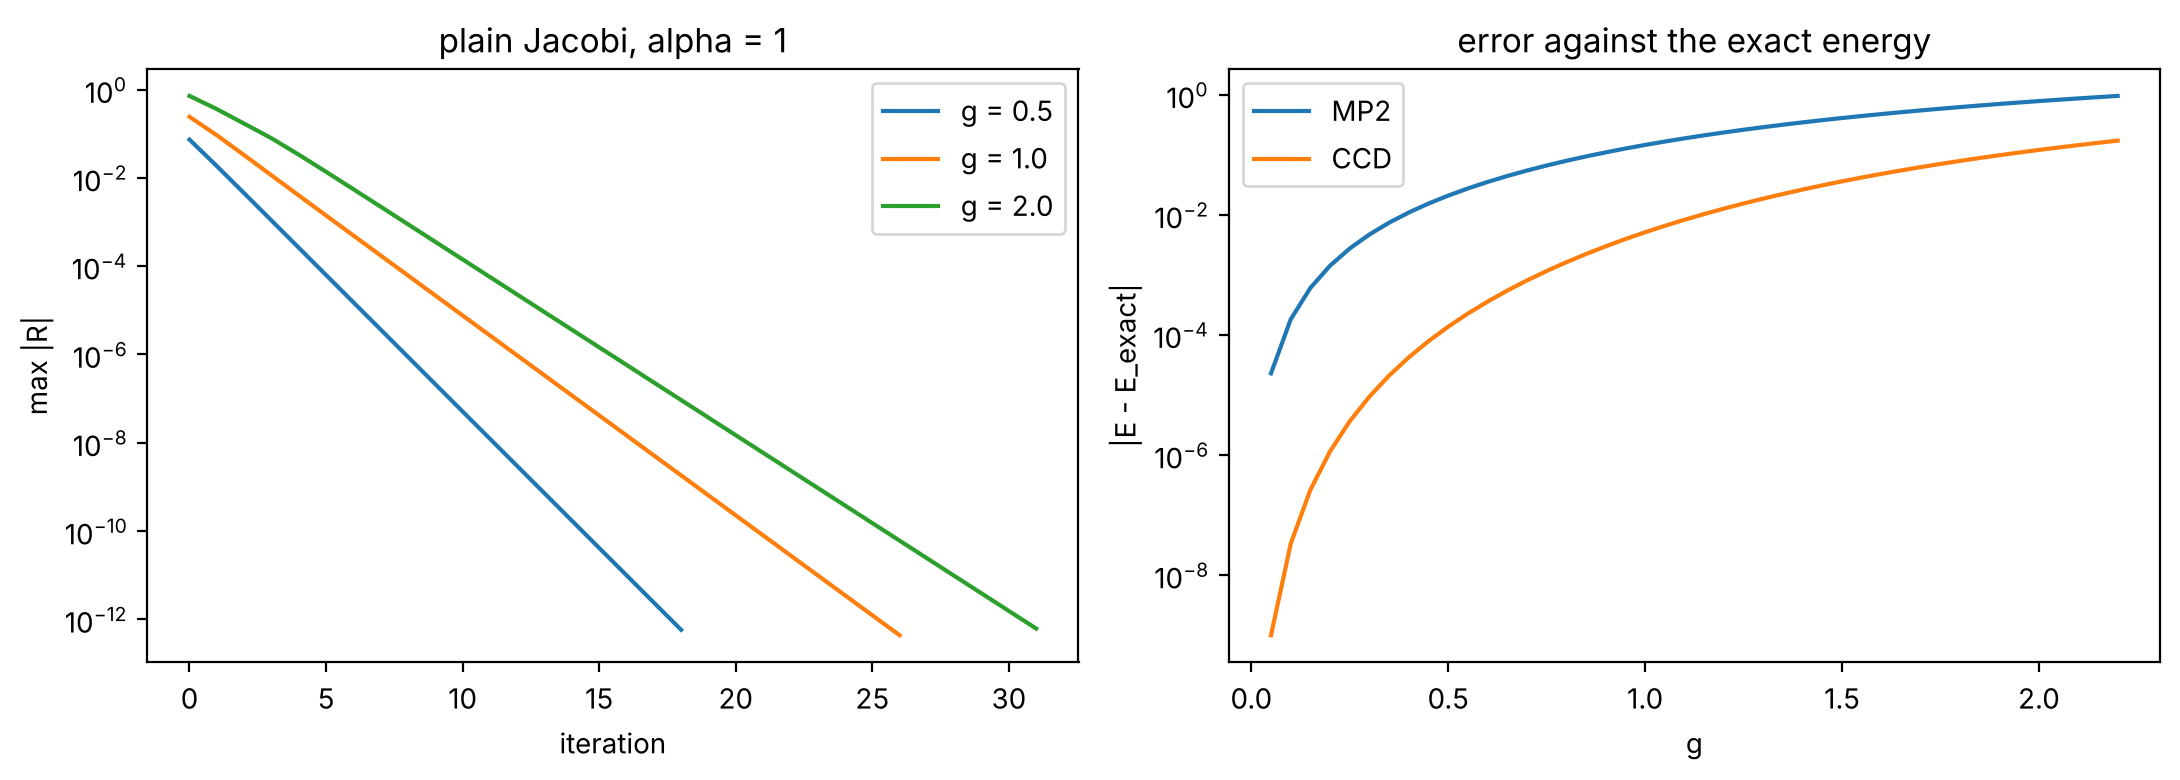

In [15]:
%matplotlib inline
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for g in (0.5, 1.0, 2.0):
    model = PairingModel(4, 4, g)
    cc = CCD(model.fock, model.v, model.n_occ)
    cc.solve()
    ax[0].semilogy([r for _, r in cc.history], label=f"g = {g}")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("max |R|"); ax[0].legend(); ax[0].set_title("plain Jacobi, alpha = 1")
gs = np.linspace(0.05, 2.2, 44)
err_ccd, err_mp2 = [], []
for g in gs:
    model = PairingModel(4, 4, g)
    cc = CCD(model.fock, model.v, model.n_occ)
    t = cc.solve()
    exact = model.exact_energy() - model.reference_energy
    err_ccd.append(abs(cc.energy(t) - exact)); err_mp2.append(abs(cc.energy(cc.first_order()) - exact))
ax[1].semilogy(gs, err_mp2, label="MP2"); ax[1].semilogy(gs, err_ccd, label="CCD")
ax[1].set_xlabel("g"); ax[1].set_ylabel("|E - E_exact|"); ax[1].legend(); ax[1].set_title("error against the exact energy")
fig.tight_layout()
plt.show()

## 8. A larger model space, and why intermediates matter

Ten levels and ten particles (five pairs): the seniority-zero space has $\binom{10}{5}=252$ configurations, the full
space $\binom{20}{10}=184\,756$ determinants, and CCD has $5\times5=25$ independent pair amplitudes.

In [16]:
print(f"{'g':>5s} {'E_ref':>10s} {'CCD':>14s} {'exact':>14s} {'CCD - exact':>12s} {'% of E_corr':>12s}")
big = {}
for g in (0.25, 0.5, 0.75, 1.0):
    model = PairingModel(10, 10, g)
    cc = CCD(model.fock, model.v, model.n_occ)
    t = cc.solve(mix=0.7)
    assert cc.converged
    e_ccd, e_fci, e_ref = model.reference_energy + cc.energy(t), model.exact_energy(), model.reference_energy
    pair = PairCCD(10, 10, g)
    assert abs(pair.e_ref + pair.energy(pair.solve(mix=0.7)) - e_ccd) < 1e-9
    big[g] = (e_ref, e_ccd, e_fci)
    print(f"{g:5.2f} {e_ref:10.4f} {e_ccd:14.8f} {e_fci:14.8f} {e_ccd - e_fci:12.2e} {100 * (e_ccd - e_ref) / (e_fci - e_ref):12.3f}")
print("\n(the pair-amplitude solver gives the same CCD energies: asserted)")

    g      E_ref            CCD          exact  CCD - exact  % of E_corr
 0.25    19.3750    19.31613773    19.31617919    -4.15e-05      100.071


 0.50    18.7500    18.46693625    18.46955181    -2.62e-03      100.933


 0.75    18.1250    17.32565966    17.36524339    -3.96e-02      105.210


 1.00    17.5000    15.57359833    15.90141656    -3.28e-01      120.507

(the pair-amplitude solver gives the same CCD energies: asserted)


CCD is still within a tenth of a per cent of the correlation energy at $g=0.25$, but with five pairs it deteriorates
faster with the coupling than it did with two: more connected quadruples (and hextuples) are missing, and the
pairing correlations become collective, the regime of BCS theory where a single determinant is a poor reference.

**A numerical trap.** $T_2$ depends only on the part of `t[i, j, a, b]` that is antisymmetric in $(i,j)$ and in
$(a,b)$. Rounding errors feed the other components, and the Jacobi map is not contracting for them. Without the
projection in `solve` the iteration for this larger space blows up:

In [17]:
model = PairingModel(10, 10, 0.75)
cc = CCD(model.fock, model.v, model.n_occ)
for mix in (1.0, 0.2):
    for project in (True, False):
        with np.errstate(all="ignore"):
            cc.solve(mix=mix, project=project, max_iter=1000)
        print(f"g = 0.75, mixing {mix}, antisymmetrise each step = {project!s:5s}:  converged = {cc.converged!s:5s} "
              f"after {cc.iterations:4d} iterations, last max|R| = {cc.history[-1][1]:.1e}")

g = 0.75, mixing 1.0, antisymmetrise each step = True :  converged = True  after   40 iterations, last max|R| = 9.7e-13


g = 0.75, mixing 1.0, antisymmetrise each step = False:  converged = False after  102 iterations, last max|R| = 5.0e+06


g = 0.75, mixing 0.2, antisymmetrise each step = True :  converged = True  after  256 iterations, last max|R| = 9.2e-13


g = 0.75, mixing 0.2, antisymmetrise each step = False:  converged = False after  358 iterations, last max|R| = 1.2e+08


The quadratic terms are sums over four internal indices for each of the $n_o^2n_v^2$ amplitudes: done naively that
is $n_o^4n_v^4$ operations. Building the intermediate first (which is what `optimize=True` asks `einsum` to find)
reduces it to $n_o^4n_v^2$.

In [18]:
model = PairingModel(12, 12, 0.5)
cc = CCD(model.fock, model.v, model.n_occ)
t = cc.first_order()
w = cc.voovv
t0 = time.perf_counter(); naive = 0.25 * np.einsum("klcd,ijcd,klab->ijab", w, t, t); t_naive = time.perf_counter() - t0
t0 = time.perf_counter()
chi = 0.5 * np.einsum("klcd,ijcd->klij", w, t)
fast = 0.5 * np.einsum("klij,klab->ijab", chi, t)
t_fast = time.perf_counter() - t0
print(f"n_o = n_v = 12:  naive {t_naive:.2f} s,  with the intermediate {1e3 * t_fast:.2f} ms,  same result: {np.allclose(naive, fast)}")

n_o = n_v = 12:  naive 0.25 s,  with the intermediate 1.36 ms,  same result: True
